In [1]:
import cv2
import numpy as np

from cv_utils import (
    display,
    display_grid,
    ImageGeometry,
    Palette,
)

from cv_utils.shapes import Point, Polygon

# Drawing Shapes using local Polygon class

In [2]:
palette = Palette()

# comes with pre-defined rainbow colors
print(palette)

red       : (209, 0, 0)
orange    : (255, 102, 34)
yellow    : (255, 218, 33)
green     : (51, 221, 0)
blue      : (17, 51, 204)
indigo    : (34, 0, 102)
violett   : (51, 0, 68)


In [3]:
palette.add_color("grey", (70, 70, 70))
palette.get_color("grey")

(70, 70, 70)

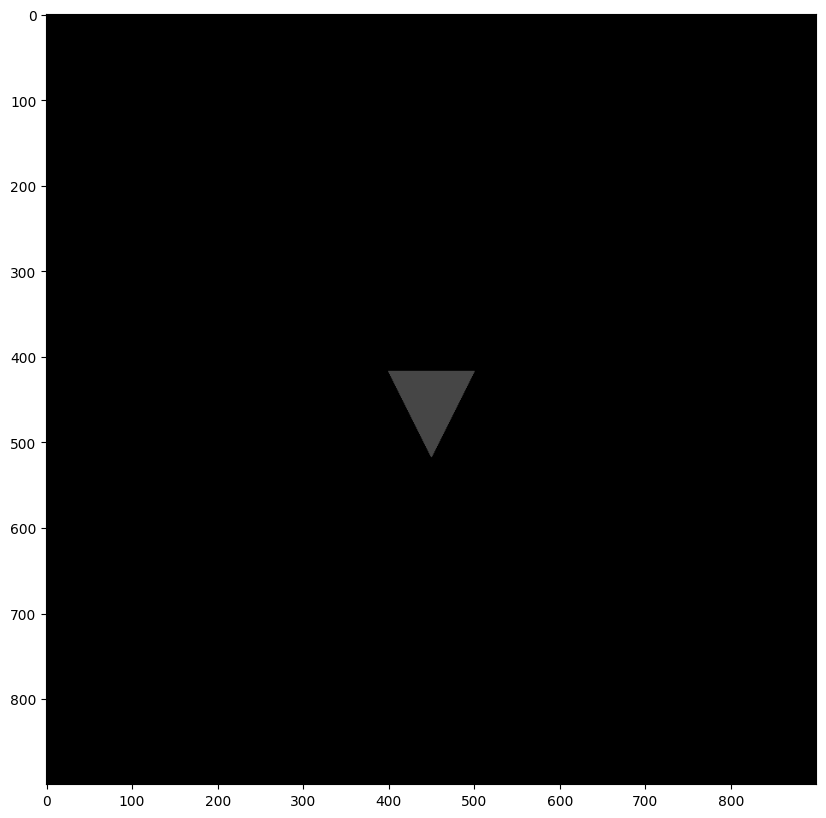

In [4]:
background = np.zeros([900, 900, 3], np.int32)
triangle = Polygon([(100, 100), (150, 200), (200, 100)])

# get image_center
image_size = np.shape(background[:,:,0])
image_center = ImageGeometry.get_center(background)

# move to center
triangle.move(image_center)
cv2.fillPoly(img=background,
             pts=[triangle.to_array()], # add extra dim []
             color=palette.get_color("grey"),
             lineType=1,
             )

display(background)

In [5]:
print("triangle: ", triangle)
print("Perimeter: ", triangle.perimeter)
print("triangle Center: ", triangle.center)

print("\nimage size: ", image_size)
print("image center: ", image_center)
print("triangle center: ", triangle.center)

triangle:  
Polygon: [Point(400, 417), Point(450, 517), Point(500, 417)]
Center: Point(450, 450)
Perimeter:  323.61
triangle Center:  Point(450, 450)

image size:  (900, 900)
image center:  (450, 450)
triangle center:  Point(450, 450)


### creating classes for regular shapes

In [6]:
from cv_utils.shapes import (RegularHexagon, RegularPentagon,
                            RegularSquare, RegularTriangle,
                            RegularShape, Circle)

from cv_utils.drawing import draw_filled_shapes


In [7]:
# new bg
new_bg = np.zeros([900, 900, 3], np.int32)

# define shapes
circle       = Circle.create(center=Point(450, 450), size=600)
reg_triangle = RegularTriangle.create(center=Point(200, 100), size=600)
reg_square   = RegularSquare.create(center=Point(400, 300), size=500)
reg_pentagon = RegularPentagon.create(center=Point(600, 600), size=400)
reg_hexagon  = RegularHexagon.create(center=Point(100, 700), size=300)
shapes = [circle, reg_triangle, reg_square, reg_pentagon, reg_hexagon]

# get preset colors
colors = [
    palette.get_color("red"),
    palette.get_color("orange"),
    palette.get_color("yellow"),
    palette.get_color("green"),
    palette.get_color("blue"),
]

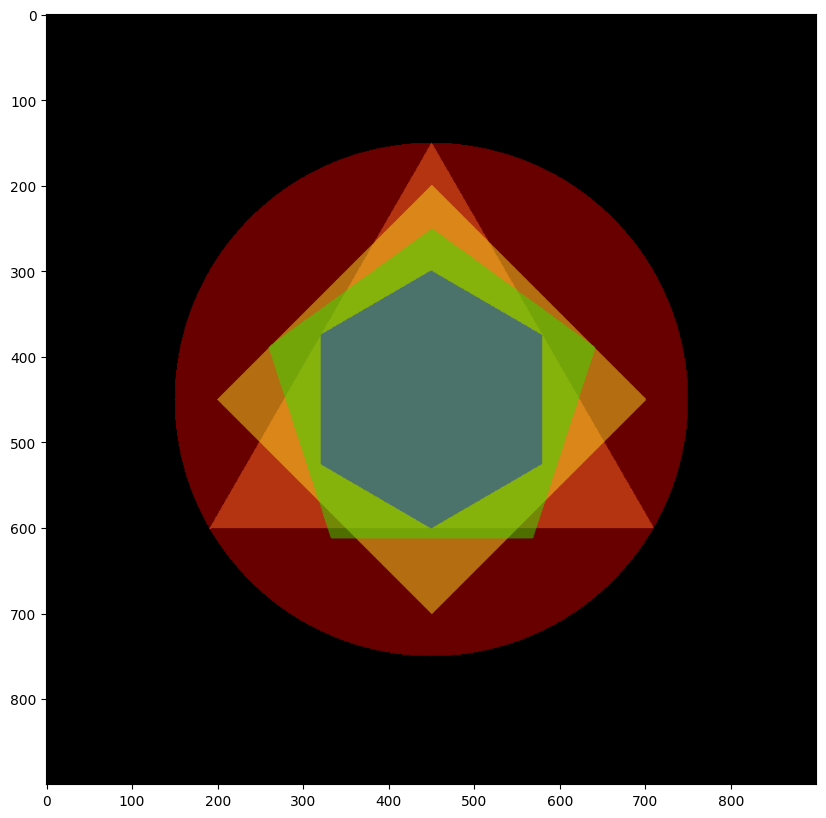

In [8]:
for shape in shapes:
    shape.center = Point(450, 450)

regulars_img = draw_filled_shapes(new_bg.copy(),
                                  shapes,
                                  colors,
                                  # alpha=0.0,
                                  # beta=0.0,
                                  # gamma=0.0
                                  )
display(regulars_img)

In [9]:
import random as rd
from cv_utils.drawing import random_regulars

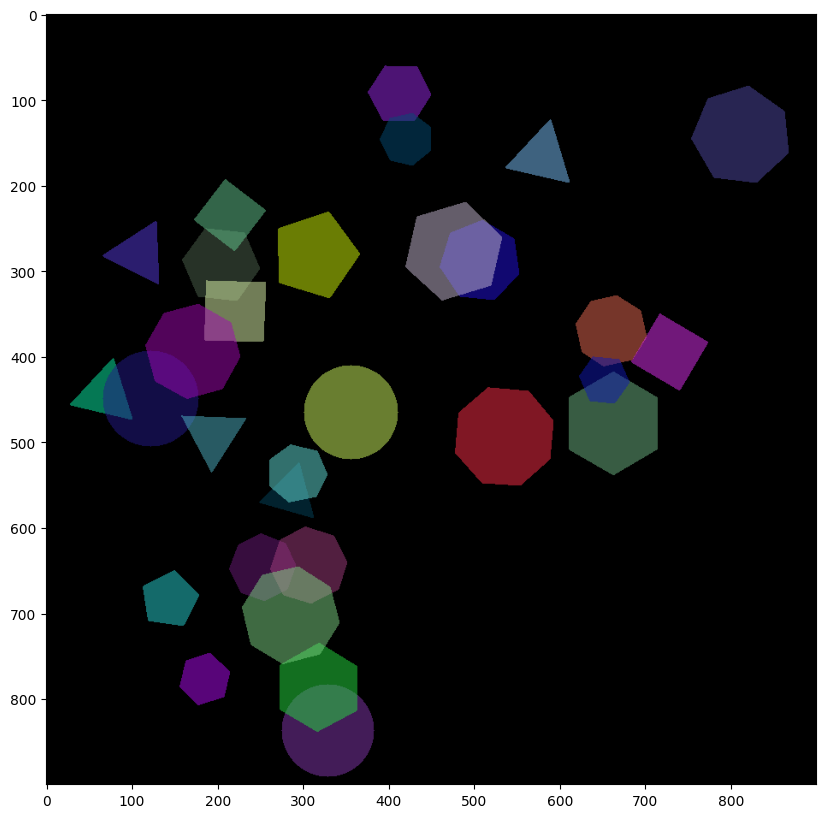

In [10]:
bg = np.zeros((900, 900, 3), dtype=np.uint8)

rand_shapes = random_regulars(img_size=(bg.shape[0],
                                        bg.shape[1]),
                              n=30,
                              shape_max_size=120,
                              shape_min_size=60
                              )

rand_colors = [(rd.randint(0, 255),
                rd.randint(0, 255),
                rd.randint(0, 255))
                for _ in range(len(rand_shapes))
]

random_img = draw_filled_shapes(bg,
                                rand_shapes,
                                rand_colors,
                                alpha=0.5,
                                beta=0.5,
                                # gamma=0.1
                                )
display(random_img)

# Edges, Countours, Corners

### Edges

In [11]:
random_grey = cv2.cvtColor(random_img, cv2.COLOR_BGR2GRAY)
# display(random_grey, "grey")

In [12]:
def get_gs_dist(img:np.ndarray):
    dist_dict = {
        "min"   : img.min(),
        "max"   : img.max(),
        "mean"  : int(img.mean()),
        "median": int(np.median(img))
    }
    print("grayscale distribution:", "\n", "-"*20)
    for keys, vals in dist_dict.items():
        print(f"{keys:<7}: {vals}")

    return dist_dict

In [13]:
gs_dict = get_gs_dist(random_grey)

grayscale distribution: 
 --------------------
min    : 0
max    : 135
mean   : 13
median : 0


In [14]:
# get edges
edges_gs = cv2.Canny(random_grey, 10, 15,
                     apertureSize=3 # distance in overlapping lines?
                     )

# Make a copy
random_edges = random_img.copy()

# use a 'white-mask' from edges, and color the edge pixels
random_edges[edges_gs == 255] = (255, 200, 0)

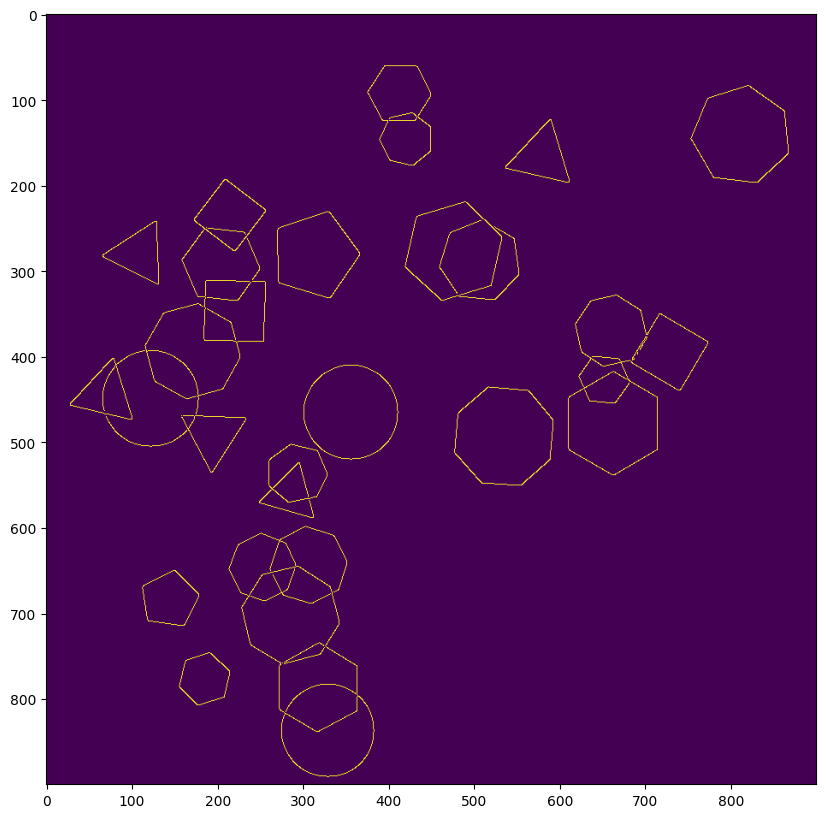

In [15]:
display(edges_gs)

### contours and contours on edges

In [16]:
contours_random, hierarchy_random = cv2.findContours(
    random_grey,              # greyscale to find
    cv2.RETR_TREE,            # mode
    cv2.CHAIN_APPROX_SIMPLE   # discovery alg.
)

contours_edges, hierarchy_edges = cv2.findContours(
    edges_gs,
    cv2.RETR_TREE,
    cv2.CHAIN_APPROX_SIMPLE
)

random_contours = cv2.drawContours(
    random_img.copy(),
    contours_random,
    -1,             # all contours
    (255, 150, 0),
    2,              # thickness
    lineType=8,     # must be 4 or 8
    hierarchy=hierarchy_random,
    maxLevel=2
)

random_contours_on_edges = cv2.drawContours(
    random_img.copy(),
    contours_edges,
    -1,
    (255, 150, 0),
    2,
    lineType=8,
    hierarchy=hierarchy_edges,
    maxLevel=2
)


### display edges and contours

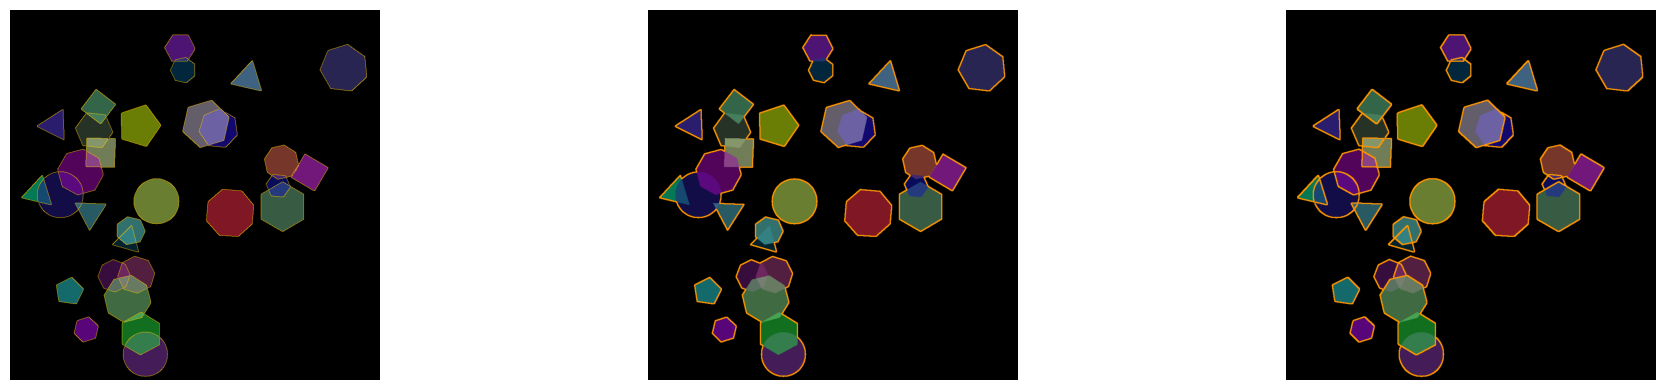

In [17]:
display_grid(images=[random_edges, random_contours, random_contours_on_edges], max_cols=3)

### Corners

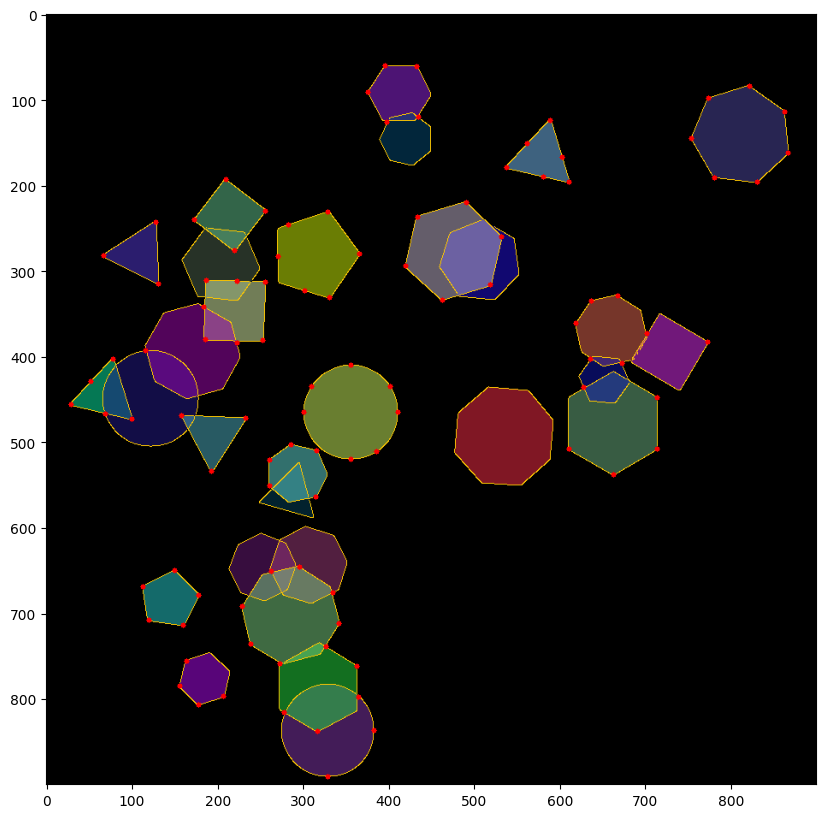

In [18]:
# Parameters for our AI model
max_corner = 150
quality_level = 0.05
min_distance = 30


corners = cv2.goodFeaturesToTrack(random_grey,
                                  max_corner,
                                  quality_level,
                                  min_distance)

# convert corners to int
corners = np.int16(corners)
contours_w_corners = random_edges.copy()

# draw corners
for corner in corners:
    x,y = corner.ravel()
    cv2.circle(contours_w_corners, (x,y), 3, (255, 0, 0), -1)

display(contours_w_corners)